# Benchmarking financial equations

An independent model-path reference is an average of discounted terminal values:

$$
\widehat u_M(0,x_0)=\frac1M\sum_{m=1}^{M}e^{-rT}g\!\left(X_T^{(m)}\right),
\qquad
\widehat{\operatorname{SE}}\!\left(\widehat u_M\right)=\frac{s_g}{\sqrt M}.
$$

Here, $M$ is the number of independently generated terminal states; $m$ labels one model path; $r$ is the discount rate; $T$ is the final time; $g$ is the terminal value; $X_T^{(m)}$ is a generated terminal state; $s_g$ is the sample standard deviation of the discounted terminal values; and $\widehat{\operatorname{SE}}$ is the estimated simulation error of their mean.

In [1]:
using RiskLabAI,Random,Statistics,LinearAlgebra,DataFrames,Dates,Plots,CSV,TOML
using RiskLabAI.Pde: FBSDESolver,FBSNNSolver,solve_pde
Base.set_zero_subnormals(false)
BLAS.set_num_threads(1)
include(joinpath("..","support","BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
include(joinpath("..","support","BookPDEStudy.jl"))
using .BookPDEStudy
@assert pkgversion(RiskLabAI)==v"1.1.0"
configure_plots!()
default(left_margin=11Plots.mm,bottom_margin=8Plots.mm)
paths=output_paths("29_deep_bsde")
method_colors=Dict("DTNN"=>palette.green,"DeepBSDE"=>palette.cyan,"FBSNN"=>palette.rose)
family_labels=Dict("default"=>"Default risk","quadratic"=>"Quadratic fixed-volatility value","maxmin"=>"Maximum-minus-minimum value","basket"=>"Basket value","best"=>"Best-of value","different"=>"Different borrowing and lending rates","hjb"=>"Hamilton-Jacobi-Bellman")
finite_sequence(values)=!isempty(values)&&all(isfinite,values)
BookSupport._number(::Missing,digits)="Not available"
function table(frame,name,caption)
    shown=copy(frame)
    for column in names(shown)
        if eltype(shown[!,column])<:Bool
            shown[!,column]=ifelse.(shown[!,column],"Yes","No")
        elseif eltype(shown[!,column])<:AbstractFloat
            shown[!,column]=[isfinite(value) ? value : missing for value in shown[!,column]]
        end
    end
    save_table(shown,paths,name;caption,label="tab:chapter29-"*replace(name,"_"=>"-"))
end
function history_summary(histories,reference=NaN)
    rows=NamedTuple[]
    for method in sort(unique([item.method for item in histories]))
        selected=filter(item->item.method==method,histories)
        values=[item.estimates[end] for item in selected]
        losses=[item.losses[end] for item in selected]
        push!(rows,(Method=method,Runs=length(selected),initial=mean(values),initial_std=length(values)>1 ? std(values) : 0.0,loss=mean(losses),loss_std=length(losses)>1 ? std(losses) : 0.0,seconds=mean(item.seconds for item in selected),parameters=first(selected).parameters,error=isfinite(reference) ? abs(mean(values)-reference) : NaN,relative=isfinite(reference) ? abs(mean(values)-reference)/max(abs(reference),1e-12) : NaN))
    end
    frame=DataFrame(rows)
    rename!(frame,["Method","Runs","Initial value mean","Initial value standard deviation","Final loss mean","Final loss standard deviation","Mean run time seconds","Parameters","Absolute error","Relative error"])
    return frame
end
function plot_histories(histories,reference,stem,title)
    panels=[plot(;xlabel="Training round",ylabel="Initial value estimate",title,legend=:outertop),plot(;xlabel="Training round",ylabel="Terminal loss",title="Validation loss",yscale=:log10,legend=:outertop)]
    for method in ("DTNN","DeepBSDE","FBSNN")
        selected=filter(item->item.method==method,histories)
        isempty(selected)&&continue
        estimates=reduce(hcat,[item.estimates for item in selected])
        losses=reduce(hcat,[item.losses for item in selected])
        center=vec(mean(estimates;dims=2)); spread=vec(std(estimates;dims=2,corrected=false))
        loss_center=vec(mean(losses;dims=2)); loss_spread=vec(std(losses;dims=2,corrected=false))
        rounds=1:length(center)
        plot!(panels[1],rounds,center;ribbon=spread,color=method_colors[method],fillalpha=.18,label=method)
        plot!(panels[2],rounds,max.(loss_center,1e-12);ribbon=(min.(loss_spread,max.(loss_center.-1e-12,0)),loss_spread),color=method_colors[method],fillalpha=.18,label=method)
        save_data(DataFrame(round=rounds,estimate=center,estimate_sd=spread,loss=loss_center,loss_sd=loss_spread),paths,stem*"_"*lowercase(method))
    end
    isfinite(reference)&&hline!(panels[1],[reference];color=palette.amber,linestyle=:dash,label="Reference")
    save_figure(plot(panels...;layout=(1,2),size=(1300,540)),paths,stem)
end


plot_histories (generic function with 1 method)

## Seven Benchmark Families

In [2]:
benchmark_families=["default","quadratic","maxmin","basket","best","different","hjb"]
initial_guesses=[40.0,70.0,1.0,.75,1.5,20.0,4.0]
reference_sources=["No independent value used","Exact formula","Independent model-path average","Exact formula","Independent model-path average","No independent value used","Independent model-path average"]
design_table=DataFrame("Benchmark"=>[family_labels[family] for family in benchmark_families],"Final time"=>[family=="different" ? .5 : 1.0 for family in benchmark_families],"Initial guess"=>initial_guesses,"Reference"=>reference_sources,"Dimension"=>fill(100,7),"Time intervals"=>fill(12,7),"Training rounds"=>fill(24,7),"Repeated seeds"=>fill(2,7))
table(design_table,"benchmark_design","The seven fresh benchmark families and their common training design.")


Row,Benchmark,Final time,Initial guess,Reference,Dimension,Time intervals,Training rounds,Repeated seeds
,String,Float64,Float64,String,Int64,Int64,Int64,Int64
1,Default risk,1.0,40.0,No independent value used,100,12,24,2
2,Quadratic fixed-volatility value,1.0,70.0,Exact formula,100,12,24,2
3,Maximum-minus-minimum value,1.0,1.0,Independent model-path average,100,12,24,2
4,Basket value,1.0,0.75,Exact formula,100,12,24,2
5,Best-of value,1.0,1.5,Independent model-path average,100,12,24,2
6,Different borrowing and lending rates,0.5,20.0,No independent value used,100,12,24,2
7,Hamilton-Jacobi-Bellman,1.0,4.0,Independent model-path average,100,12,24,2


## Comparing exact benchmarks with independent checks

In [3]:
reference_values=Dict{String,Float64}();reference_rows=NamedTuple[]
for (index,family) in enumerate(benchmark_families)
    eq=equation(family,100,family=="different" ? .5 : 1.0,12)
    value,error,draws,source=NaN,NaN,0,"No independent value used"
    if family=="quadratic"
        value=exp((eq.rate+eq.sigma^2)*eq.total_time)*sum(abs2,eq.x_init);error=0.0;source="Exact formula"
    elseif family=="basket"
        value=mean(eq.x_init);error=0.0;source="Exact formula"
    elseif family in ("maxmin","best")
        value,error=monte_carlo_reference(family*"100",family,1.0,.4;rate=.05,initial=eq.x_init);draws=80000;source="Independent model-path average"
    elseif family=="hjb"
        value,error=monte_carlo_reference("hjb100","hjb",1.0,sqrt(2.0));draws=100000;source="Independent model-path average"
    end
    reference_values[family]=value
    push!(reference_rows,(name=family_labels[family],source=source,value=value,error=error,draws=draws))
end
reference_table=DataFrame(reference_rows);rename!(reference_table,["Benchmark","Reference source","Reference value","Estimated standard error","Generated terminal states"])
table(reference_table,"benchmark_references","Exact and independently generated references used in the seven-family comparison.")


Row,Benchmark,Reference source,Reference value,Estimated standard error,Generated terminal states
,String,String,Float64?,Float64?,Int64
1,Default risk,No independent value used,missing,missing,0
2,Quadratic fixed-volatility value,Exact formula,77.1049,0.0,0
3,Maximum-minus-minimum value,Independent model-path average,2.11978,0.00162519,80000
4,Basket value,Exact formula,0.75,0.0,0
5,Best-of value,Independent model-path average,2.31251,0.00162215,80000
6,Different borrowing and lending rates,No independent value used,missing,missing,0
7,Hamilton-Jacobi-Bellman,Independent model-path average,4.59019,0.000453614,100000


## Repeated Method Comparisons

Row,Benchmark,Method,Seed,Final initial value,Final terminal loss,Absolute error,Relative error,Run time seconds,Parameters
,String,String,Int64,Float64,Float64,Float64?,Float64?,Float64,Int64
1,Default risk,DTNN,17,55.1319,310.617,missing,missing,37.428,546582
2,Default risk,DeepBSDE,17,41.6852,255.24,missing,missing,5.446,47040
3,Default risk,FBSNN,17,-0.132628,3681.07,missing,missing,5.732,1921
4,Default risk,DTNN,43,55.0562,314.452,missing,missing,4.531,546582
5,Default risk,DeepBSDE,43,42.2316,225.385,missing,missing,0.326,47040
6,Default risk,FBSNN,43,0.185586,3608.85,missing,missing,0.473,1921
7,Quadratic fixed-volatility value,DTNN,17,71.0667,52.1824,6.03815,0.0783109,7.104,546582
8,Quadratic fixed-volatility value,DeepBSDE,17,70.3952,51.0119,6.70971,0.0870206,1.544,47040
9,Quadratic fixed-volatility value,FBSNN,17,0.73423,5419.41,76.3706,0.990478,2.199,1921


Row,Benchmark,Method,Runs,Initial value mean,Initial value standard deviation,Final loss mean,Final loss standard deviation,Mean run time seconds,Parameters,Absolute error,Relative error
,String,String,Int64,Float64,Float64,Float64,Float64,Float64,Int64,Float64?,Float64?
1,Default risk,DTNN,2,55.094,0.0535353,312.534,2.71183,20.9795,546582,missing,missing
2,Default risk,DeepBSDE,2,41.9584,0.38641,240.313,21.1107,2.886,47040,missing,missing
3,Default risk,FBSNN,2,0.026479,0.225011,3644.96,51.0698,3.1025,1921,missing,missing
4,Quadratic fixed-volatility value,DTNN,2,70.6974,0.522286,54.2565,2.93331,6.2375,546582,6.40746,0.0831006
5,Quadratic fixed-volatility value,DeepBSDE,2,70.4575,0.0881995,58.2071,10.1755,0.9845,47040,6.64735,0.0862118
6,Quadratic fixed-volatility value,FBSNN,2,1.02232,0.407413,5327.5,129.982,1.3845,1921,76.0826,0.986741
7,Maximum-minus-minimum value,DTNN,2,1.46893,0.00123288,1.64573,0.323198,6.238,546582,0.650853,0.307037
8,Maximum-minus-minimum value,DeepBSDE,2,2.16214,0.0193398,0.207679,0.0342054,1.228,47040,0.0423548,0.0199807
9,Maximum-minus-minimum value,FBSNN,2,1.30995,0.0104472,0.75933,0.0350593,1.427,1921,0.809837,0.382037


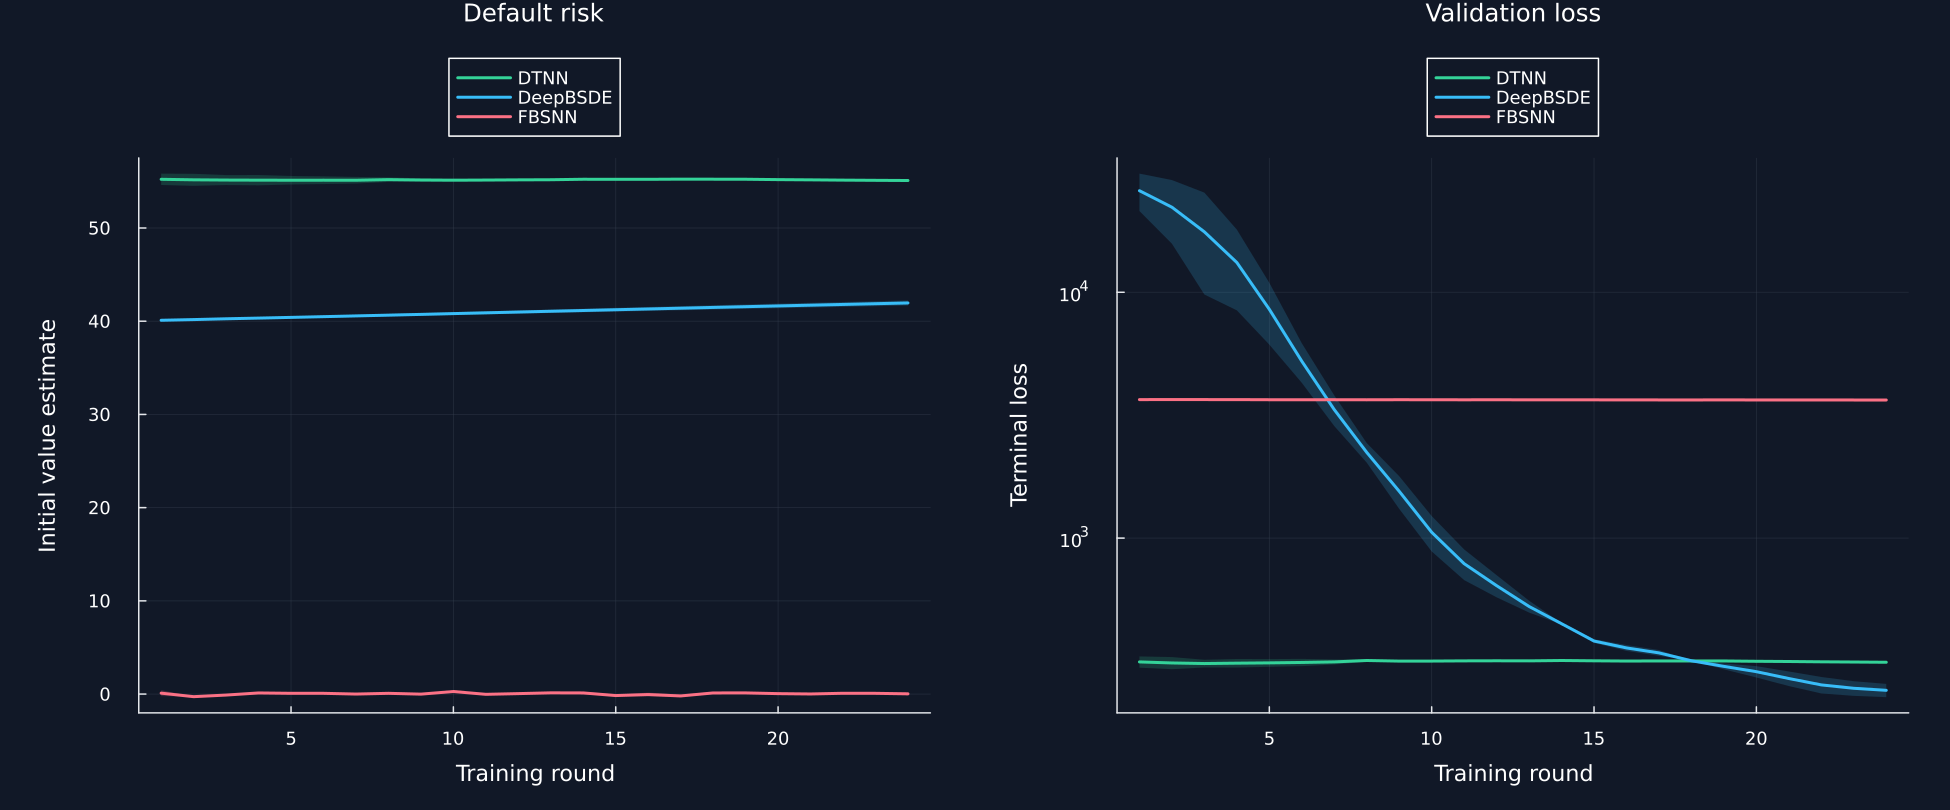

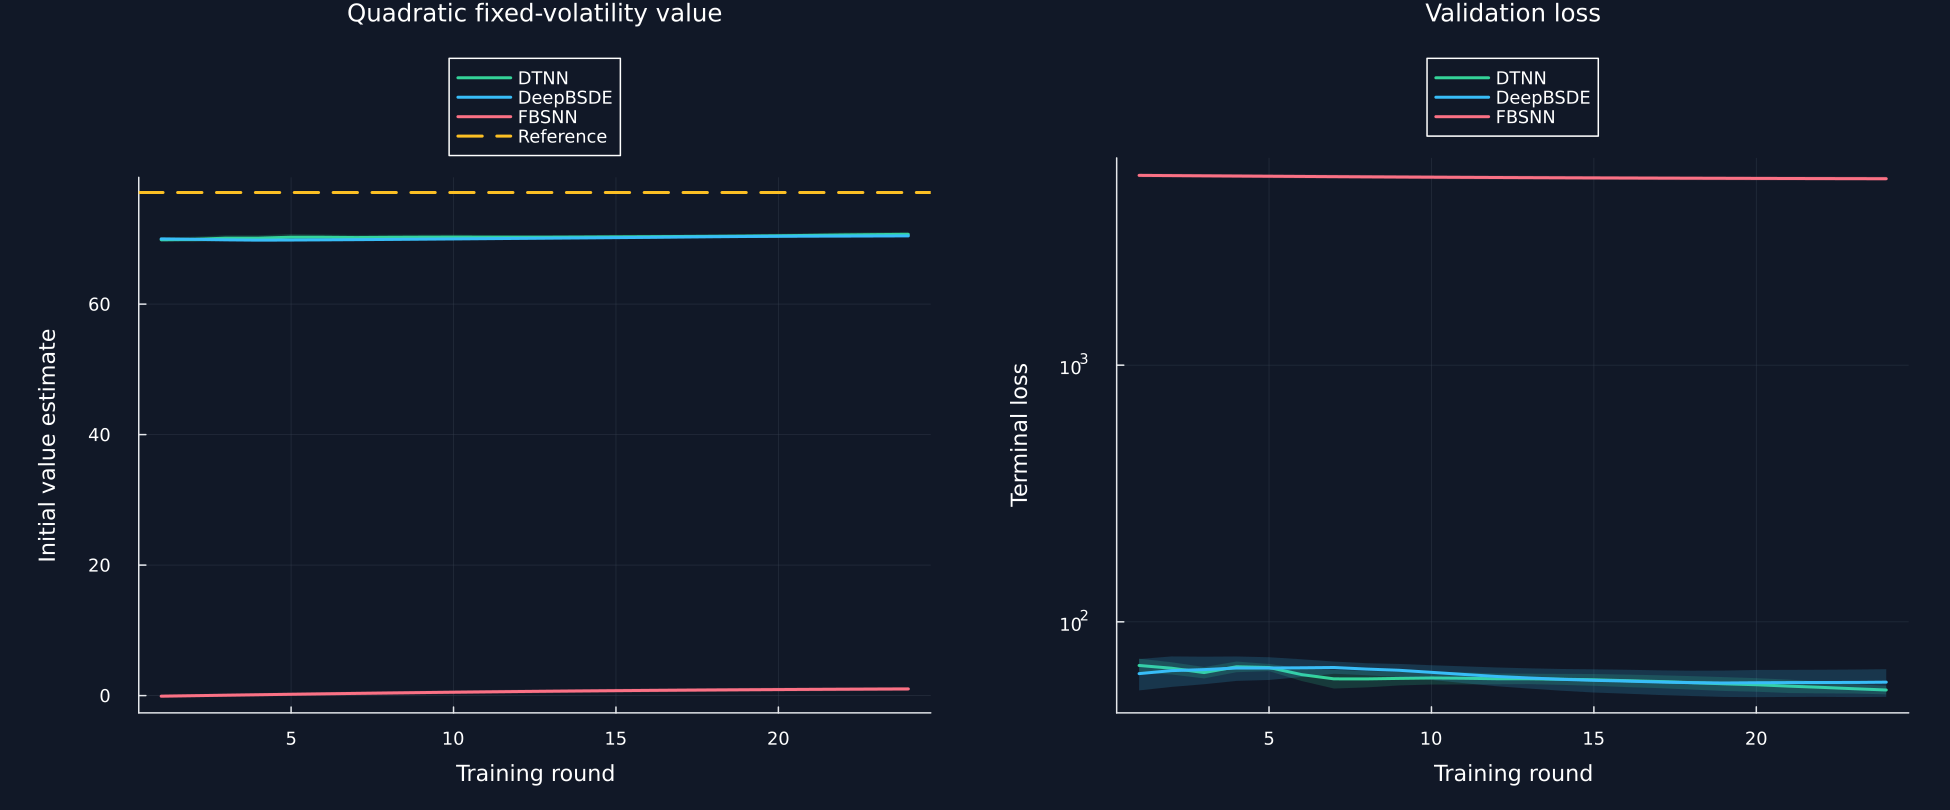

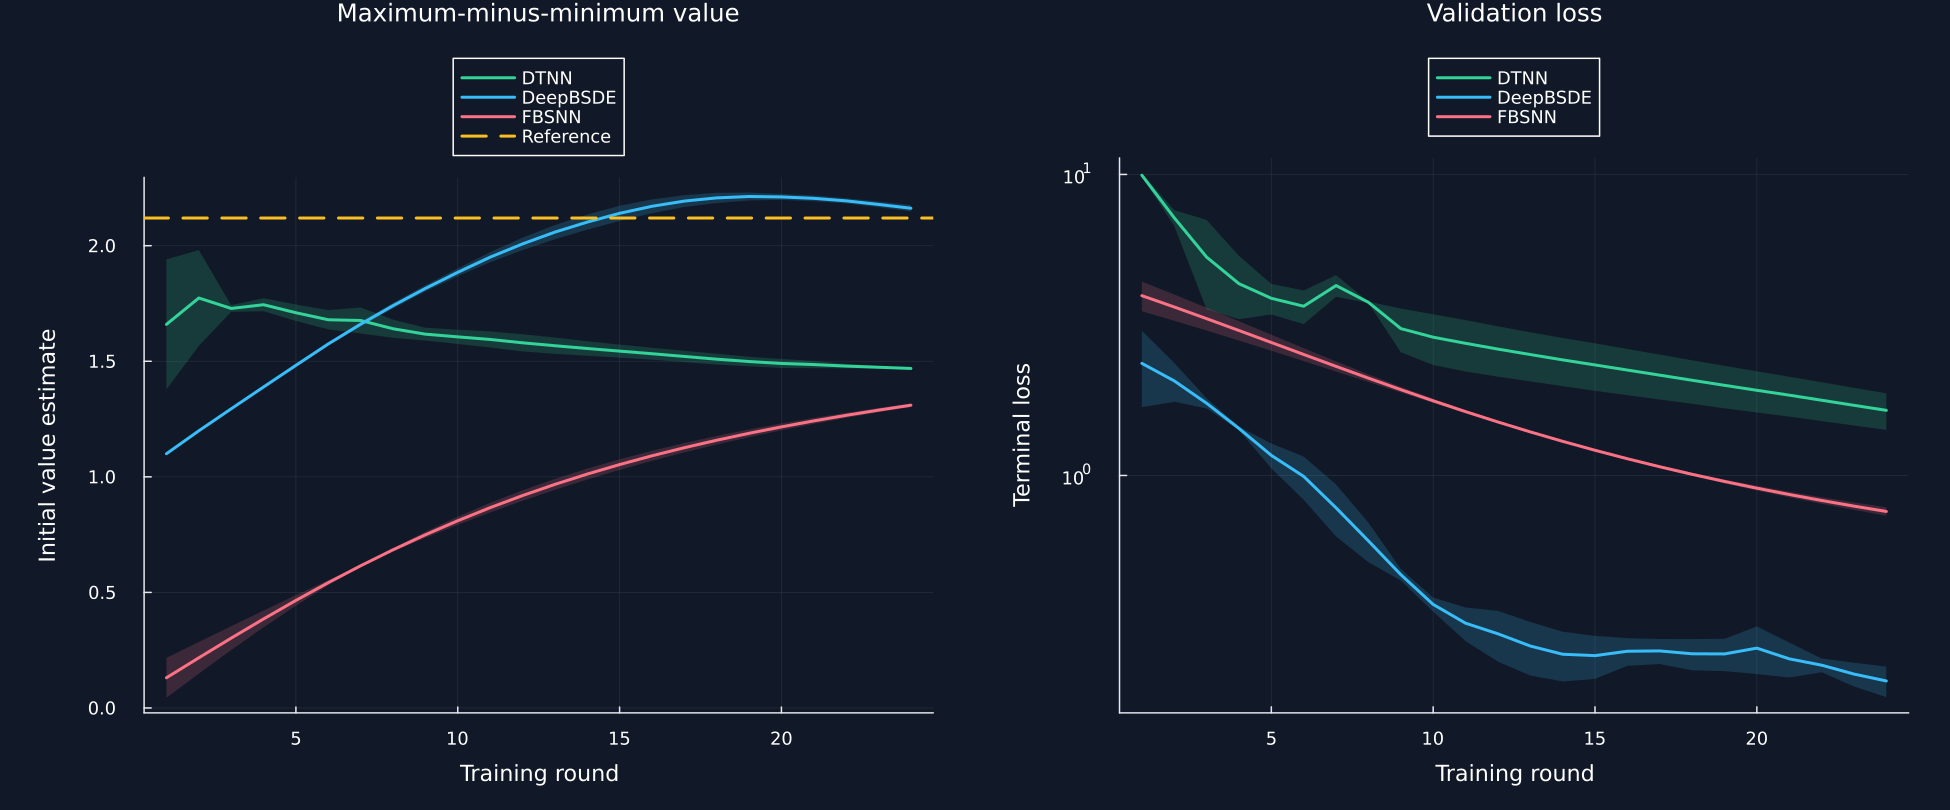

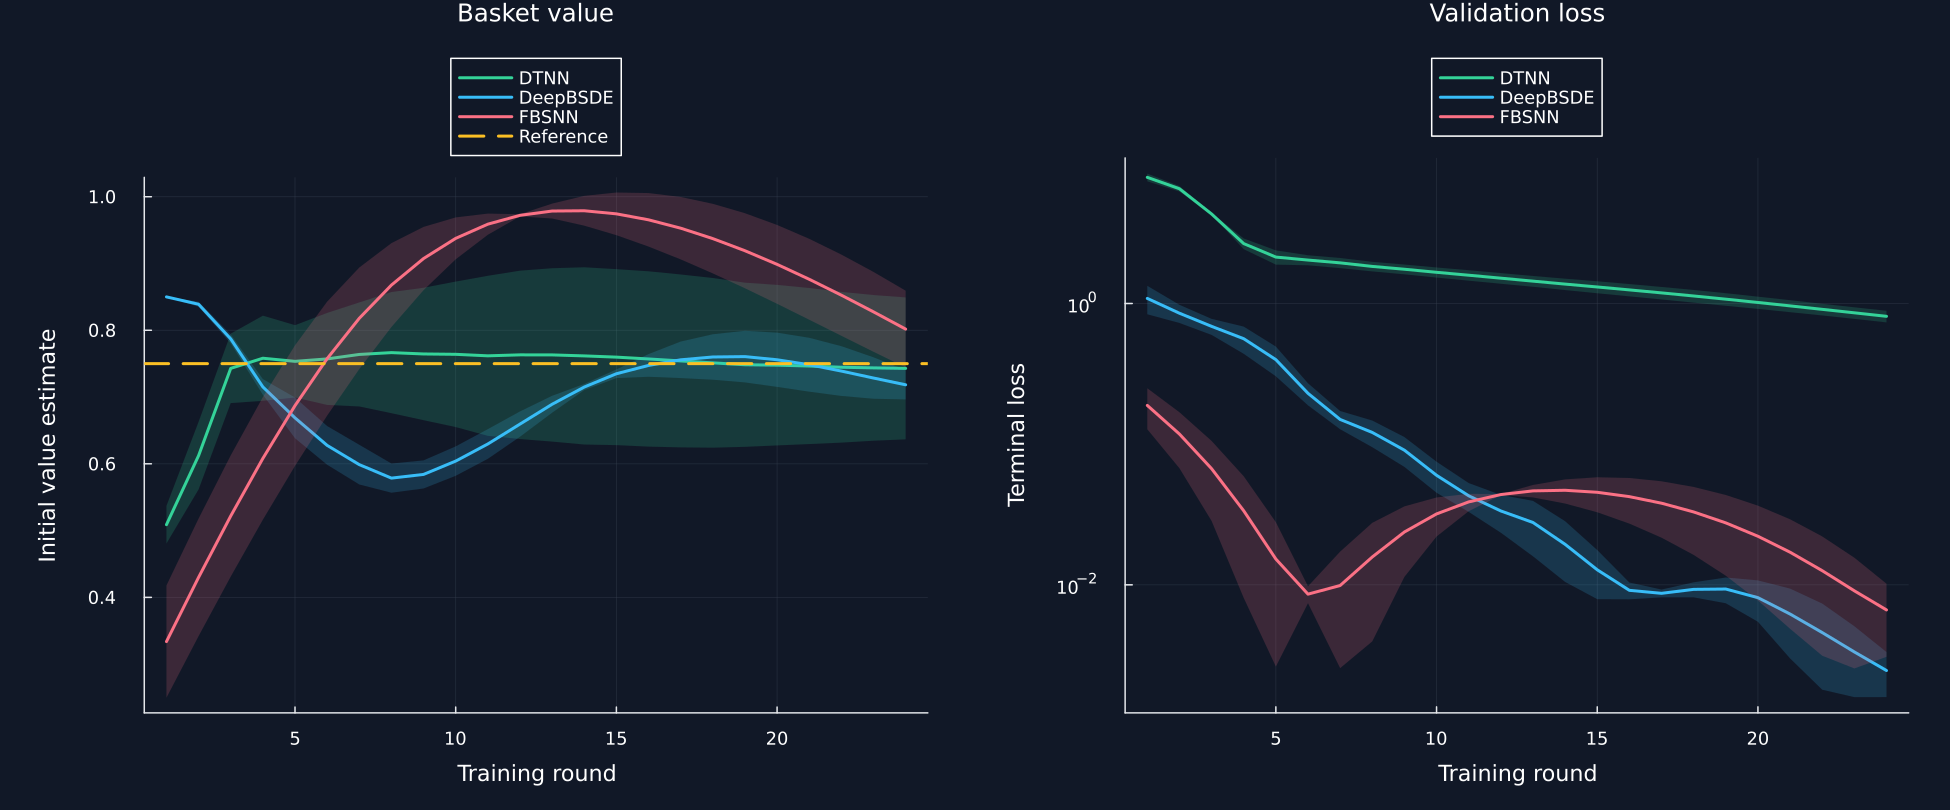

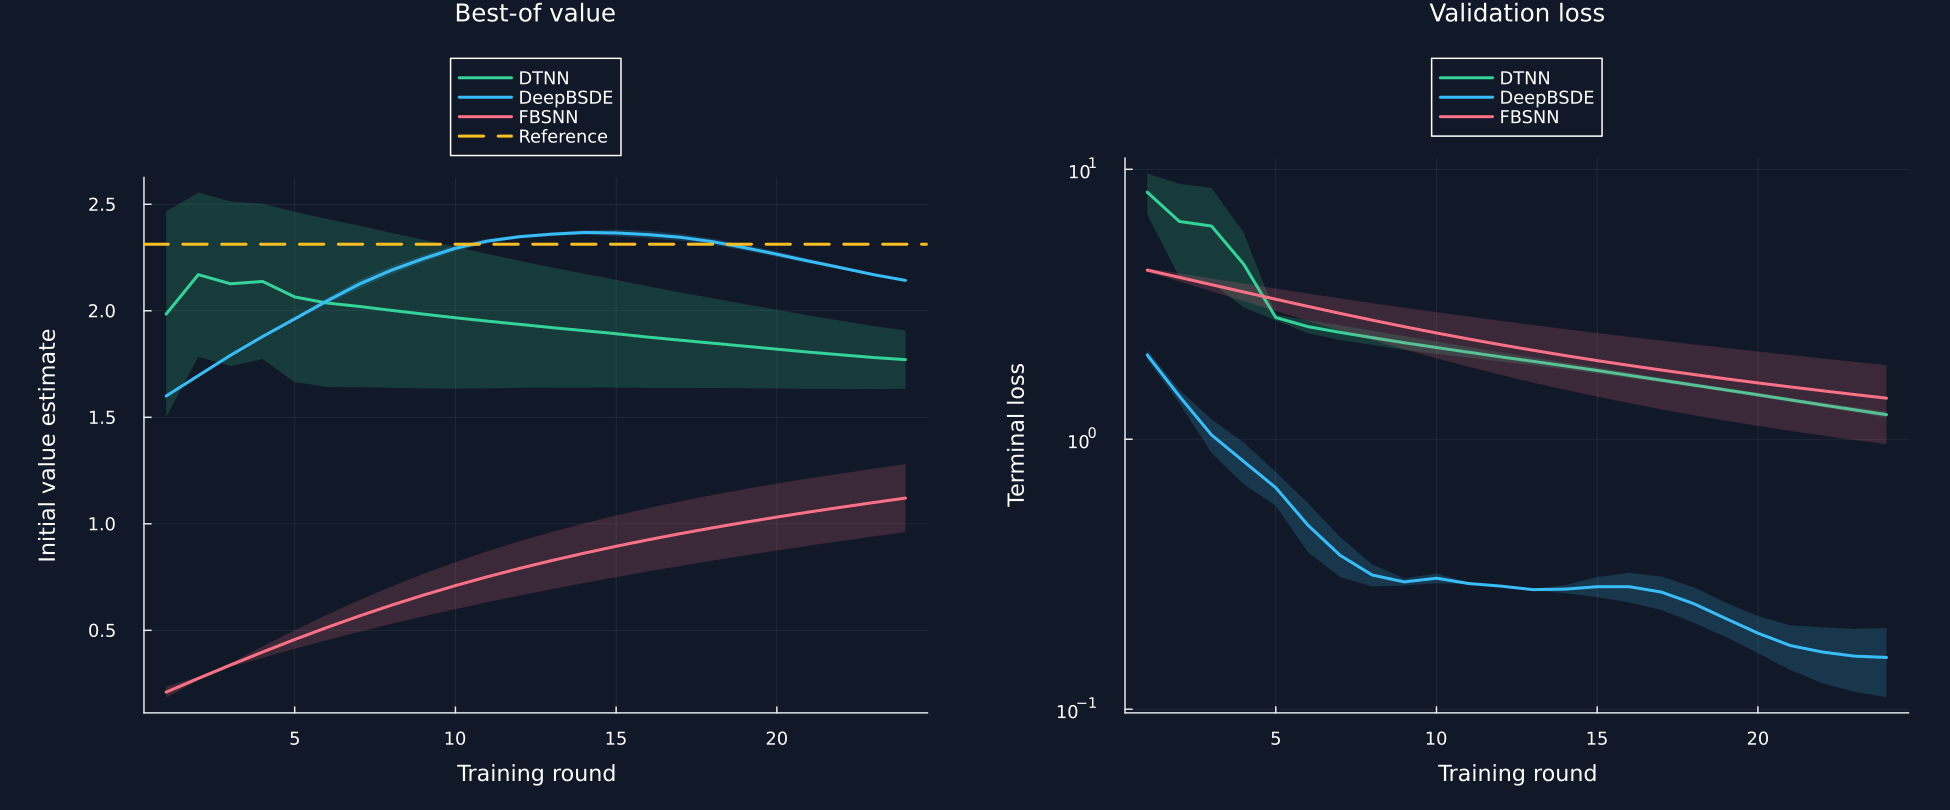

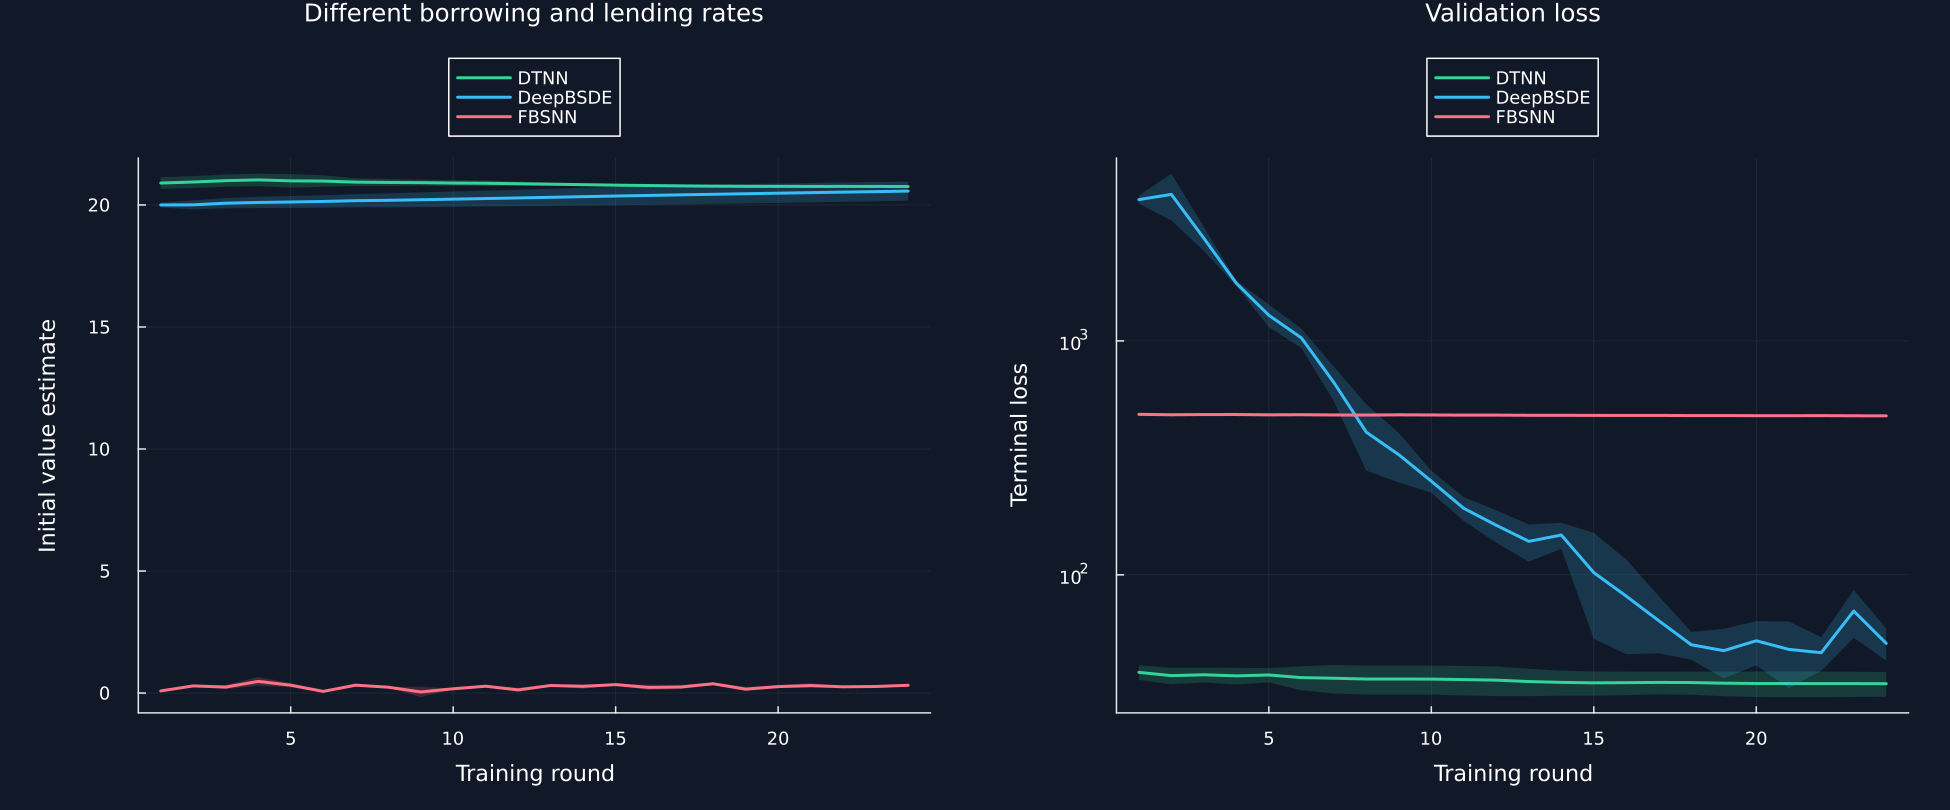

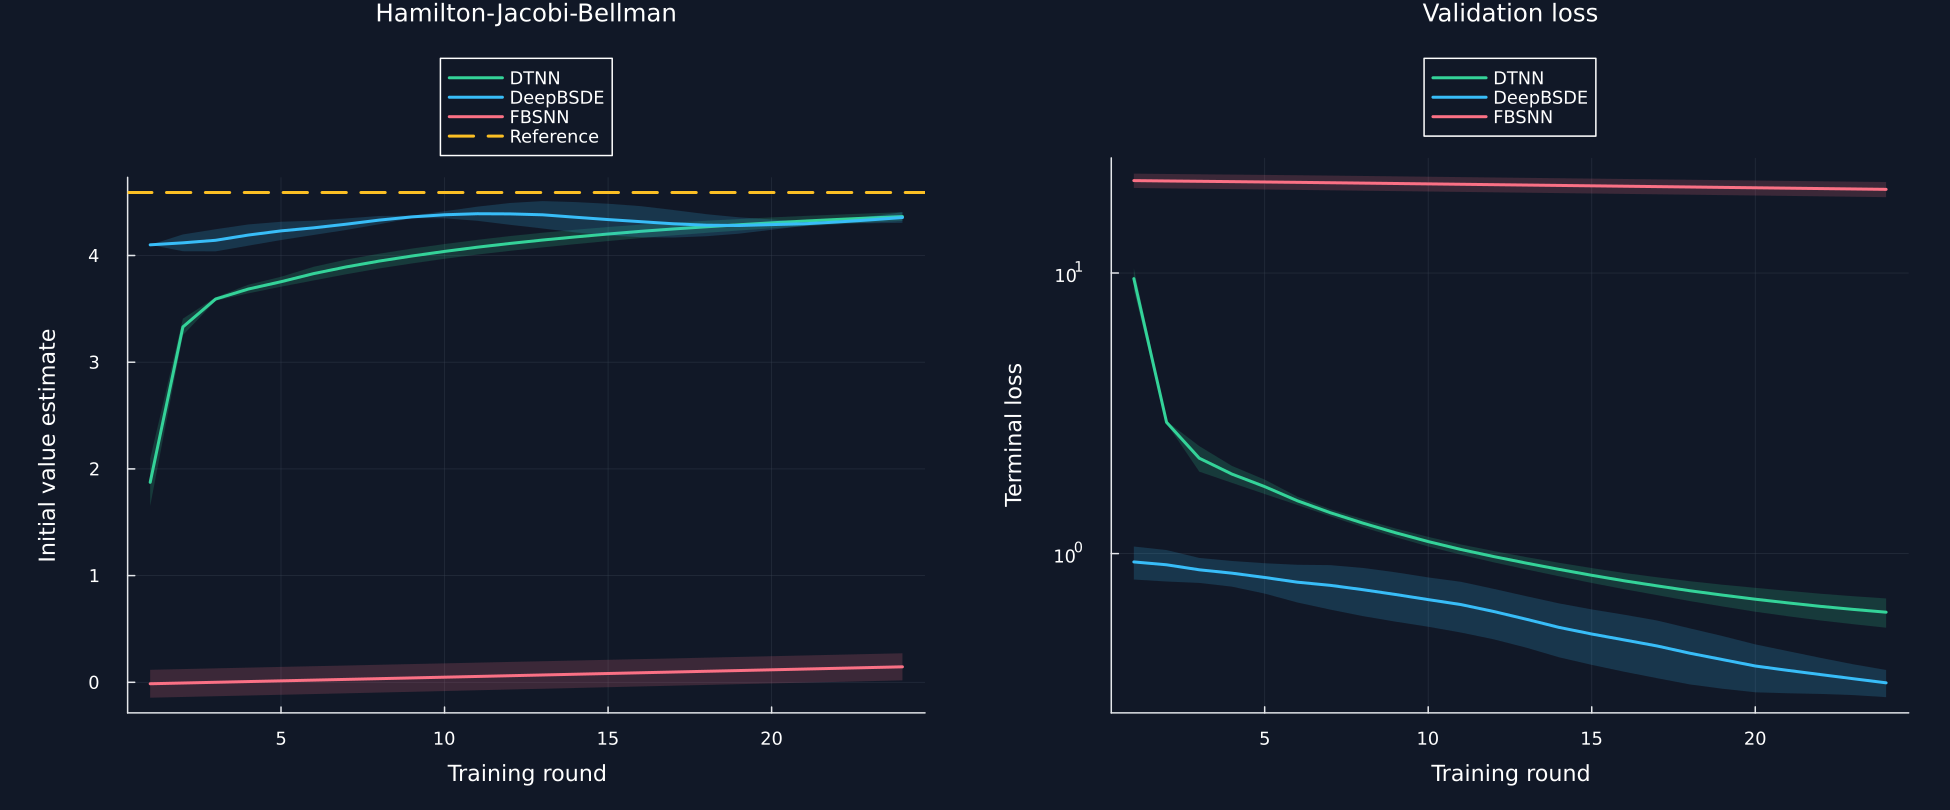

In [4]:
all_histories=[run_case(record,paths.figure_data) for record in records("benchmark")]
run_table=DataFrame("Benchmark"=>[family_labels[item.family] for item in all_histories],"Method"=>[item.method for item in all_histories],"Seed"=>[item.seed for item in all_histories],"Final initial value"=>[item.estimates[end] for item in all_histories],"Final terminal loss"=>[item.losses[end] for item in all_histories],"Absolute error"=>[isfinite(reference_values[item.family]) ? abs(item.estimates[end]-reference_values[item.family]) : NaN for item in all_histories],"Relative error"=>[isfinite(reference_values[item.family]) ? abs(item.estimates[end]-reference_values[item.family])/max(abs(reference_values[item.family]),1e-12) : NaN for item in all_histories],"Run time seconds"=>[item.seconds for item in all_histories],"Parameters"=>[item.parameters for item in all_histories])
summary_frames=DataFrame[]
for family in benchmark_families
    frame=history_summary(filter(item->item.family==family,all_histories),reference_values[family])
    insertcols!(frame,1,"Benchmark"=>fill(family_labels[family],nrow(frame)))
    push!(summary_frames,frame)
end
summary_table=vcat(summary_frames...;cols=:union)
table(run_table,"benchmark_repeated_runs","Fresh repeated training runs for all seven benchmark families.")
table(summary_table,"benchmark_method_summary","Method means, dispersion, run times, and errors across the seven families.")
stems=Dict("default"=>"default_risk","quadratic"=>"quadratic_value","maxmin"=>"max_min_value","basket"=>"basket_value","best"=>"best_of_value","different"=>"different_rates","hjb"=>"hjb_100d")
for family in benchmark_families
    plot_histories(filter(item->item.family==family,all_histories),reference_values[family],"benchmark_"*stems[family]*"_training",family_labels[family])
end


## Testing numerical sensitivity to problem size

Row,Benchmark,Method,Training rounds,Initial value,Terminal loss,Absolute error
,String,String,Int64,Float64,Float64,Float64?
1,Basket value,DTNN,6,0.757103,2.03568,0.0689129
2,Basket value,DTNN,12,0.763178,1.51337,0.126084
3,Basket value,DTNN,18,0.751198,1.13088,0.127046
4,Basket value,DTNN,24,0.742925,0.810666,0.106278
5,Basket value,DeepBSDE,6,0.627584,0.229818,0.122416
6,Basket value,DeepBSDE,12,0.659505,0.0335138,0.0904954
7,Basket value,DeepBSDE,18,0.759997,0.00928674,0.0340426
8,Basket value,DeepBSDE,24,0.718334,0.00246008,0.0316661
9,Basket value,FBSNN,6,0.757537,0.00858649,0.0853243


Row,Dimension,Method,Reference value,Initial value,Absolute error,Final terminal loss,Run time seconds
,Int64,String,Float64,Float64,Float64,Float64,Float64
1,5,DTNN,4.31787,4.14766,0.170216,1.59012,2.755
2,5,DeepBSDE,4.31787,3.88279,0.43508,1.69475,0.079
3,5,FBSNN,4.31787,0.390996,3.92688,17.029,0.126
4,20,DTNN,15.421,14.4593,0.961644,12.7673,2.475
5,20,DeepBSDE,15.421,14.2104,1.21061,10.0363,0.134
6,20,FBSNN,15.421,0.65331,14.7677,218.078,0.22
7,100,DTNN,77.1049,71.2041,5.90074,112.006,2.806
8,100,DeepBSDE,77.1049,75.5821,1.52277,77.5569,0.253
9,100,FBSNN,77.1049,1.30902,75.7959,5282.54,0.299


Row,Time intervals,Step length,Method,Reference value,Initial value,Absolute error,Final terminal loss,Run time seconds
,Int64,Float64,String,Float64,Float64,Float64,Float64,Float64
1,6,0.166667,DTNN,15.421,14.1518,1.2692,9.03086,1.723
2,6,0.166667,DeepBSDE,15.421,14.3227,1.09824,7.03487,2.003
3,6,0.166667,FBSNN,15.421,0.283499,15.1375,211.214,0.155
4,12,0.0833333,DTNN,15.421,14.1097,1.31123,13.2903,2.71
5,12,0.0833333,DeepBSDE,15.421,14.254,1.16702,11.0347,0.138
6,12,0.0833333,FBSNN,15.421,0.381802,15.0392,217.32,0.203
7,24,0.0416667,DTNN,15.421,14.0735,1.34746,12.1765,4.367
8,24,0.0416667,DeepBSDE,15.421,14.3333,1.08765,9.54935,5.517
9,24,0.0416667,FBSNN,15.421,0.136741,15.2842,219.326,0.662


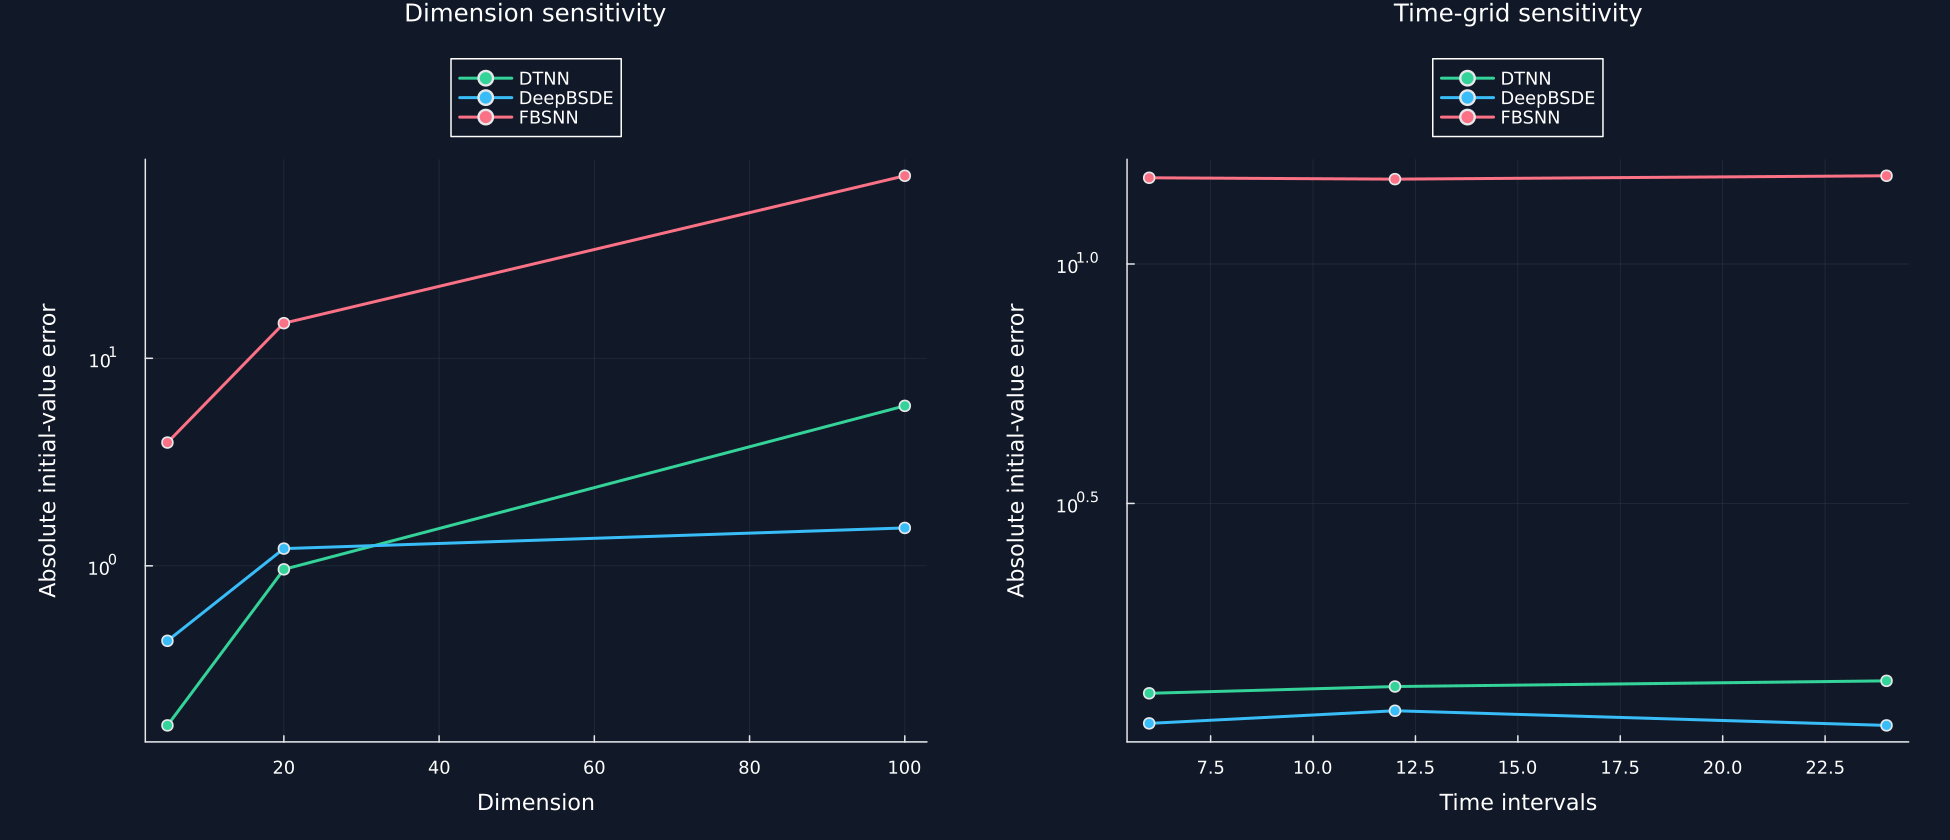

In [5]:
budget_rows=DataFrame("Benchmark"=>String[],"Method"=>String[],"Seed"=>Int[],"Training rounds"=>Int[],"Initial value"=>Float64[],"Terminal loss"=>Float64[],"Absolute error"=>Float64[])
for item in all_histories,checkpoint in (6,12,18,24)
    reference=reference_values[item.family]
    push!(budget_rows,(family_labels[item.family],item.method,item.seed,checkpoint,item.estimates[checkpoint],item.losses[checkpoint],isfinite(reference) ? abs(item.estimates[checkpoint]-reference) : NaN))
end
budget_table=combine(groupby(budget_rows,["Benchmark","Method","Training rounds"]),[column=>mean=>column for column in ["Initial value","Terminal loss","Absolute error"]]...)
sort!(budget_table,["Benchmark","Method","Training rounds"])
table(budget_table,"benchmark_budget_sensitivity","Mean estimates and losses as the training budget grows.")
dimension_histories=[run_case(record,paths.figure_data) for record in records("dimension")]
dimension_rows=NamedTuple[]
for item in dimension_histories
    eq=equation("quadratic",item.dimension,1.0,12);reference=exp((eq.rate+eq.sigma^2)*eq.total_time)*sum(abs2,eq.x_init)
    push!(dimension_rows,(dimension=item.dimension,method=item.method,reference=reference,estimate=item.estimates[end],error=abs(item.estimates[end]-reference),loss=item.losses[end],seconds=item.seconds))
end
dimension_table=DataFrame(dimension_rows);rename!(dimension_table,["Dimension","Method","Reference value","Initial value","Absolute error","Final terminal loss","Run time seconds"])
table(dimension_table,"benchmark_dimension_sensitivity","Quadratic fixed-volatility results at three dimensions.")
grid_histories=[run_case(record,paths.figure_data) for record in records("grid")]
grid_rows=NamedTuple[]
for item in grid_histories
    eq=equation("quadratic",20,1.0,item.intervals);reference=exp((eq.rate+eq.sigma^2)*eq.total_time)*sum(abs2,eq.x_init)
    push!(grid_rows,(intervals=item.intervals,dt=eq.delta_t,method=item.method,reference=reference,estimate=item.estimates[end],error=abs(item.estimates[end]-reference),loss=item.losses[end],seconds=item.seconds))
end
grid_table=DataFrame(grid_rows);rename!(grid_table,["Time intervals","Step length","Method","Reference value","Initial value","Absolute error","Final terminal loss","Run time seconds"])
table(grid_table,"benchmark_time_grid_sensitivity","Quadratic fixed-volatility results on three time grids.")
p1=plot(;xlabel="Dimension",ylabel="Absolute initial-value error",yscale=:log10,title="Dimension sensitivity",legend=:outertop)
p2=plot(;xlabel="Time intervals",ylabel="Absolute initial-value error",yscale=:log10,title="Time-grid sensitivity",legend=:outertop)
for method in ("DTNN","DeepBSDE","FBSNN")
    a=filter(row->row.Method==method,dimension_table);sort!(a,"Dimension")
    b=filter(row->row.Method==method,grid_table);sort!(b,"Time intervals")
    plot!(p1,a.Dimension,a[!,"Absolute error"];marker=:circle,color=method_colors[method],label=method)
    plot!(p2,b[!,"Time intervals"],b[!,"Absolute error"];marker=:circle,color=method_colors[method],label=method)
end
save_figure(plot(p1,p2;layout=(1,2),size=(1300,560)),paths,"dimension_and_grid_sensitivity")


## Checking terminal-value helpers against references

Row,Generated terminal states,Reference estimate,Estimated standard error
,Int64,Float64,Float64
1,2000,2.29858,0.00992587
2,8000,2.29983,0.00501016
3,32000,2.31121,0.00257416
4,80000,2.31455,0.00162244


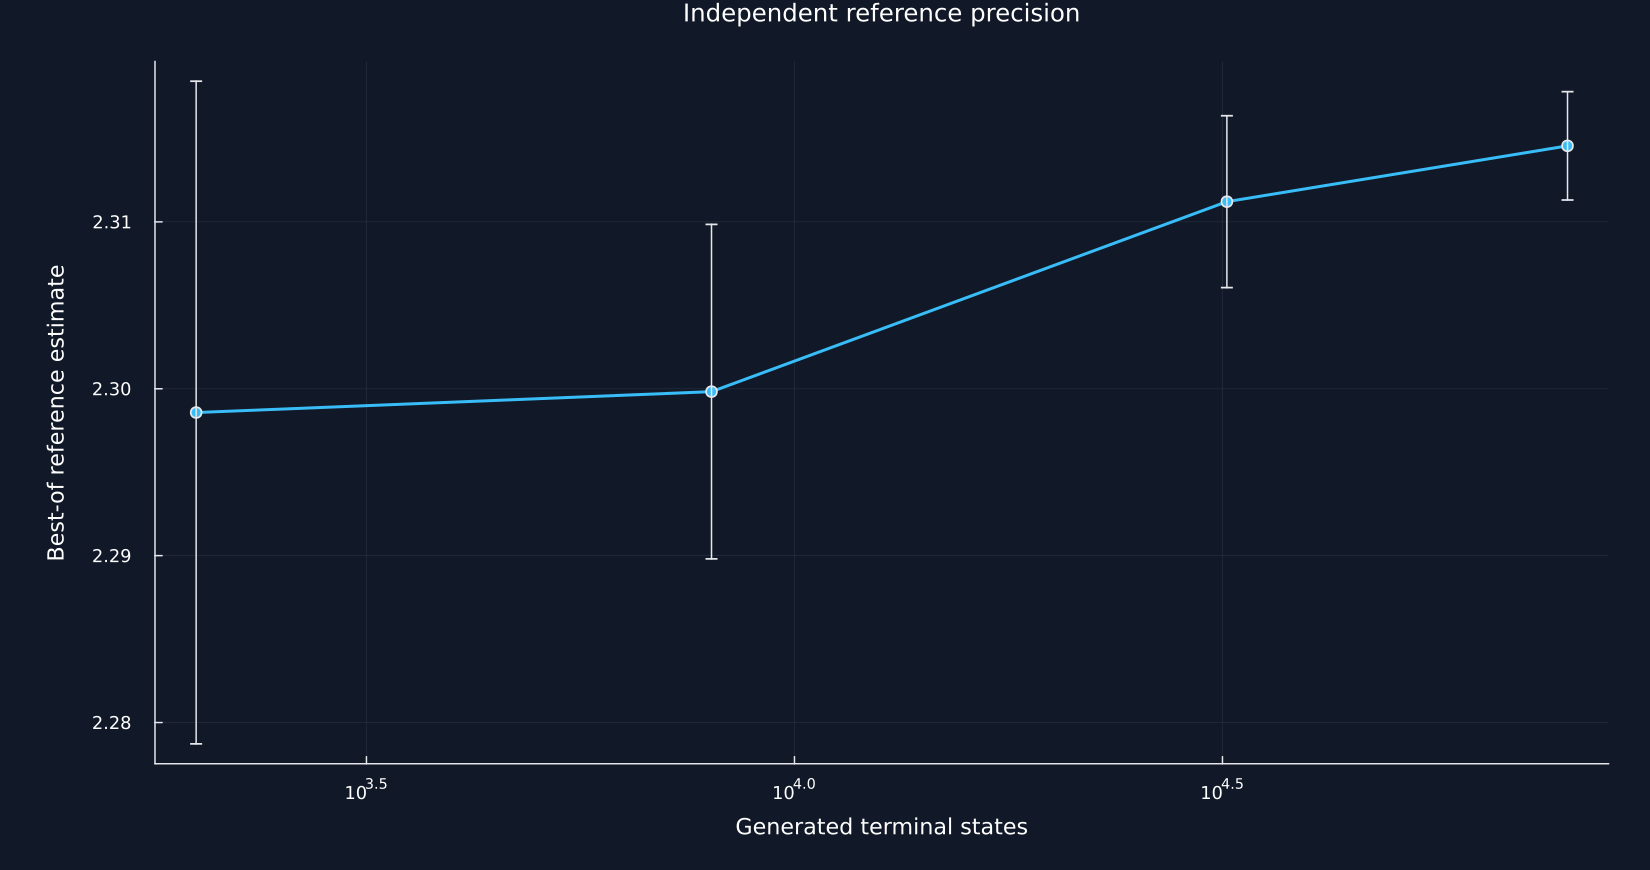

Row,Case,Direct terminal value,Multi-sample helper value,Values agree
,String,Float32,Float32,String
1,Maximum state 160,20.0,40.0,No
2,Maximum state 130,10.0,10.0,Yes


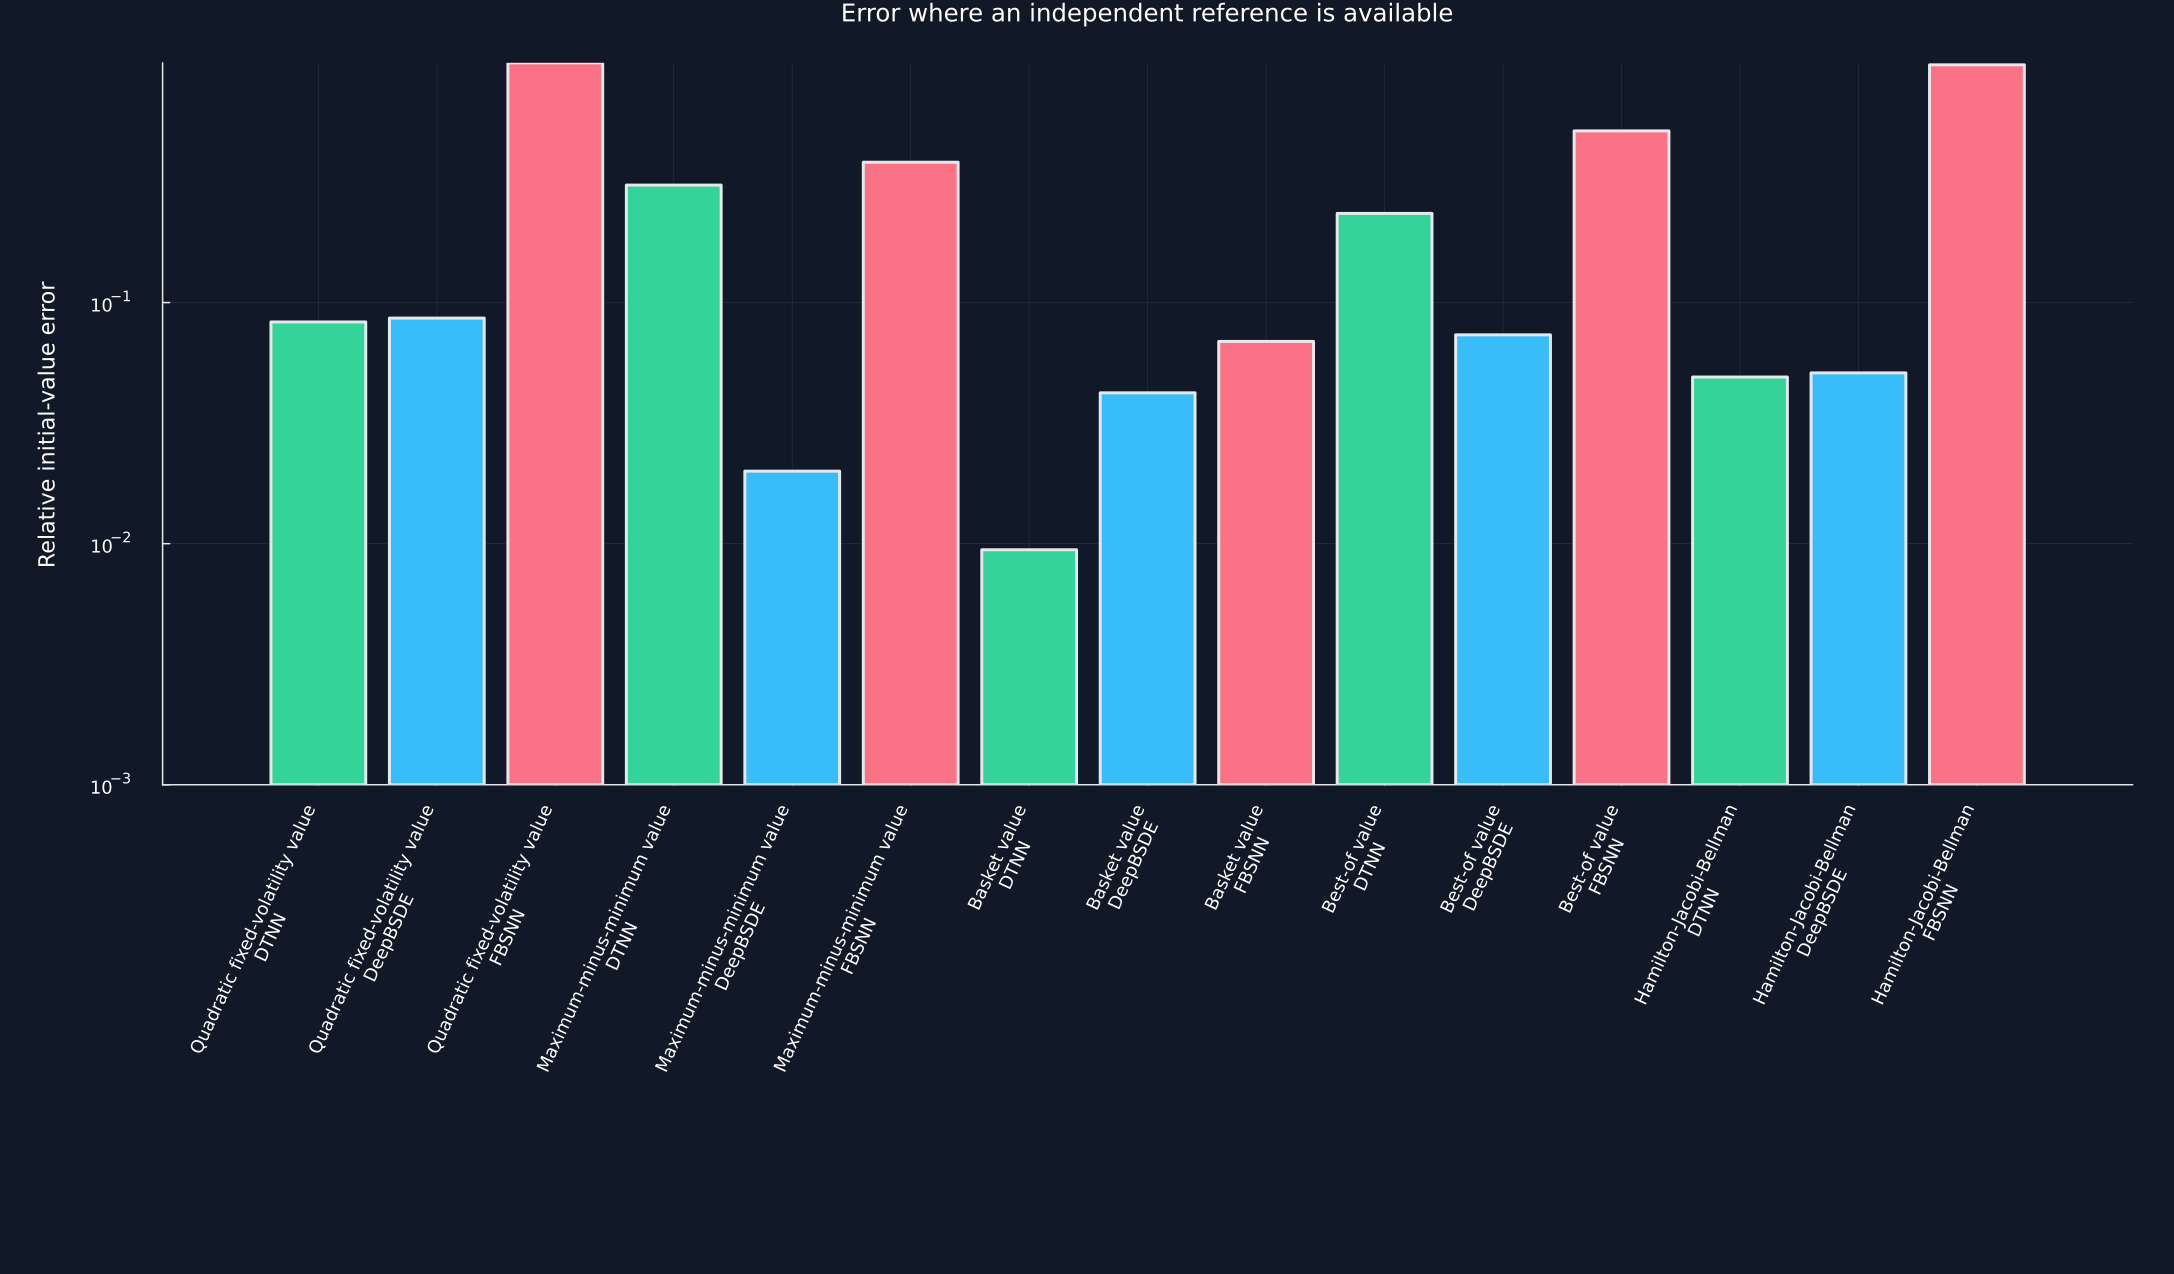

In [6]:
convergence_rows=NamedTuple[]
initial=[1.0/(1.0+mod(index-1,2)) for index in 1:100]
for count in (2000,8000,32000,80000)
    value,error=monte_carlo_reference("convergence_"*string(count),"best",1.0,.4;rate=.05,initial)
    push!(convergence_rows,(count=count,value=value,error=error))
end
convergence_table=DataFrame(convergence_rows);rename!(convergence_table,["Generated terminal states","Reference estimate","Estimated standard error"])
table(convergence_table,"reference_monte_carlo_convergence","Best-of reference estimate as the number of generated terminal states grows.")
figure=plot(convergence_table[!,"Generated terminal states"],convergence_table[!,"Reference estimate"];yerror=2convergence_table[!,"Estimated standard error"],marker=:circle,color=palette.cyan,xscale=:log10,xlabel="Generated terminal states",ylabel="Best-of reference estimate",title="Independent reference precision",legend=false,size=(1100,580))
save_figure(figure,paths,"reference_monte_carlo_convergence")
eq=PricingDiffRate(6,.5,12)
test_state=Float32[160 90 80 70 60 50;130 120 110 100 90 80]
direct=vec(E.terminal(eq,test_state));helper=vec(E.terminal_for_sample(eq,test_state))
helper_table=DataFrame("Case"=>["Maximum state 160","Maximum state 130"],"Direct terminal value"=>direct,"Multi-sample helper value"=>helper,"Values agree"=>isapprox.(direct,helper))
table(helper_table,"different_rate_terminal_helper","The released different-rate terminal helper omits the second payoff term above 150.")
available=filter(row->isfinite(row["Absolute error"]),summary_table)
labels=[row.Benchmark*"\n"*row.Method for row in eachrow(available)]
figure=bar(1:nrow(available),available[!,"Relative error"];color=[method_colors[method] for method in available.Method],yscale=:log10,xticks=(1:nrow(available),labels),xrotation=65,ylabel="Relative initial-value error",title="Error where an independent reference is available",legend=false,size=(1450,850),bottom_margin=50Plots.mm)
save_figure(figure,paths,"benchmark_relative_errors")


## Tests

In [7]:
@assert length(benchmark_families)==7&&nrow(run_table)==42
@assert Set(run_table.Method)==Set(["DTNN","DeepBSDE","FBSNN"])
@assert Set(run_table.Benchmark)==Set(design_table.Benchmark)
@assert all(isfinite,run_table[!,"Final initial value"])&&all(isfinite,run_table[!,"Final terminal loss"])
@assert count(isfinite,reference_table[!,"Reference value"])==5
@assert isapprox(reference_values["quadratic"],exp(.21)*62.5)
@assert isapprox(reference_values["basket"],.75)
@assert nrow(dimension_table)==9&&nrow(grid_table)==9
@assert helper_table[!,"Values agree"]==[false,true]
@assert convergence_table[end,"Estimated standard error"]<convergence_table[1,"Estimated standard error"]
@assert all(finite_sequence(item.losses)&&finite_sequence(item.estimates) for item in all_histories)
display(DataFrame(Test=["Seven families","Three methods","Two seeds","Finite estimates","Five independent references","Quadratic formula","Basket formula","Dimension checks","Time-grid checks","Different-rate helper mismatch","Reference precision"],Passed=trues(11)))


Row,Test,Passed
,String,Bool
1,Seven families,true
2,Three methods,true
3,Two seeds,true
4,Finite estimates,true
5,Five independent references,true
6,Quadratic formula,true
7,Basket formula,true
8,Dimension checks,true
9,Time-grid checks,true
